In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import glob
from pathlib import Path
# Plotting functions
# Keep text editable in AI
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42 # embed TrueType fonts in PDF
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none' # write <text> in SVG (not paths)[3:26 AM]import matplotlib as mpl

# Train vs pheno heatmap

### To do:
- define AGMs
- cycle thru lmer coef train results
- find the clusters of interest
- plot train vs pheno heatmap

In [11]:
#main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309'
main_dir = Path('C:/Users/gabri/Documents/Data_projects/MCcharactertization/ROSMAP/Top_sets/Set309')
cluster_list = pd.read_csv(os.path.join(main_dir, 'Pipeline_files/Summary_files/all_clusters_pass_pval_nosex.csv'))
clus_list = cluster_list.Cluster.to_list()

path = os.path.join(main_dir, "Pipeline_files/LMER_res")

In [12]:
def build_agm_lmer_matrix(
    agm_list,
    path,
    data_type="train",
    alpha=0.05,
    sig_only=True
):
    """
    Build a heatmap-ready dataframe of LMER coefficients for AGMs.

    Parameters
    ----------
    agm_list : list of str
        List of AGMs like:
        'Excitatory_ExcL45RORBGABRG1_Cluster_7'
    path : str
        Directory containing the LMER coef and adjusted p-value files.
    data_type : str, default='train'
        Either 'train' or 'validation'.
    alpha : float, default=0.05
        Significance threshold for adjusted p-values.
    sig_only : bool, default=True
        If True, non-significant coefficients are replaced with NaN.
        If False, all coefficients are kept.

    Returns
    -------
    heatmap_df : pd.DataFrame
        Rows = AGMs
        Columns = phenotypes
        Values = coefficients (NaN for non-significant if sig_only=True)
    """

    agm_rows = {}

    for agm in agm_list:

        if "_Cluster_" not in agm:
            print(f"Skipping malformed AGM name: {agm}")
            continue

        subtype, cluster_num = agm.rsplit("_Cluster_", 1)
        cluster_name = f"Cluster_{cluster_num}"

        coef_file = os.path.join(
            path, f"{subtype}_{data_type}_lmer_coef_nosex.csv"
        )
        
        if data_type == 'train':
            adjp_file = os.path.join(path, f"{subtype}_{data_type}_adj_pvals_nosex.csv")
        else:
            adjp_file = os.path.join(path, f"{subtype}_{data_type}_lmer_pvals_nosex.csv")


        if not os.path.exists(coef_file):
            print(f"Missing coef file for {agm}: {coef_file}")
            continue

        if not os.path.exists(adjp_file):
            print(f"Missing adj pval file for {agm}: {adjp_file}")
            continue

        coef_df = pd.read_csv(coef_file, index_col=0)
        adjp_df = pd.read_csv(adjp_file, index_col=0)

        if cluster_name not in coef_df.index:
            print(f"{cluster_name} not found in coef file for {agm}")
            continue

        if cluster_name not in adjp_df.index:
            print(f"{cluster_name} not found in adjp file for {agm}")
            continue

        coef_row = coef_df.loc[cluster_name].copy()
        adjp_row = adjp_df.loc[cluster_name].copy()

        common_cols = coef_row.index.intersection(adjp_row.index)
        coef_row = coef_row[common_cols]
        adjp_row = adjp_row[common_cols]

        if sig_only:
            coef_row[adjp_row >= alpha] = np.nan

        agm_rows[agm] = coef_row

    heatmap_df = pd.DataFrame.from_dict(agm_rows, orient="index")
    return heatmap_df

In [13]:
train_df = build_agm_lmer_matrix(
    agm_list=clus_list,
    path=path,
    data_type="train",
    alpha=0.05,
    sig_only=True
)

In [14]:
validation_df = build_agm_lmer_matrix(
    agm_list=clus_list,
    path=path,
    data_type="validation",
    alpha=0.05,
    sig_only=True
)

In [15]:
pheno_mapping = {
    'age_death': 'Age at Death',
    'msex': 'Sex: Men',
    'braaksc': 'Braak score',
    'ceradsc': 'CERAD score',
    'gpath': 'Global pathology',
    'niareagansc': 'NIA-Reagan score',
    'amyloid': 'Amyloid',
    'tangles': 'Tangles',
    'tdp_st4': 'TDP-43 load stages',
    'arteriol_scler': 'Arteriolosclerosis',
    'caa_4gp': 'Cerebral Amyloid Angiopathy (CAA)',
    'cvda_4gp2': 'Cerebral Atherosclerosis Rating',
    'ci_num2_mct': 'Chronic Microinfarcts',
    'E2': 'Apoe E2',
    'E4': 'Apoe E4',
    'new_cogdx': 'Clinical diagnosis'
}

clus_labels = {
    'Excitatory_ExcL45RORBGABRG1_Cluster_0'  : 'Exc L4-5 RORB GABRG1 C0',
    'Excitatory_ExcL45RORBGABRG1_Cluster_7'  : 'Exc L4-5 RORB GABRG1 C7',
    'Excitatory_ExcL45RORBGABRG1_Cluster_8'  : 'Exc L4-5 RORB GABRG1 C8',
    'Excitatory_ExcL45RORBGABRG1_Cluster_13' : 'Exc L4-5 RORB GABRG1 C13',
    'Excitatory_ExcL45RORBGABRG1_Cluster_5'  : 'Exc L4-5 RORB GABRG1 C5',
    'Excitatory_ExcL45RORBGABRG1_Cluster_9'  : 'Exc L4-5 RORB GABRG1 C9',
    'Excitatory_ExcL45RORBGABRG1_Cluster_17' : 'Exc L4-5 RORB GABRG1 C17',

    'Excitatory_ExcL35RORBPLCH1_Cluster_14'  : 'Exc L3-5 RORB PLCH1 C14',
    'Excitatory_ExcL6CT_Cluster_14'          : 'Exc L6 CT C14',
    'Excitatory_ExcL34RORBCUX2_Cluster_6'    : 'Exc L3-4 RORB CUX2 C6',
    'Excitatory_ExcNRGN_Cluster_15'          : 'Exc NRGN C15',

    'Inhibitory_InhG7_Cluster_10'            : 'Inh G7 C10',
    'Inhibitory_InhG7_Cluster_12'            : 'Inh G7 C12',
    'Inhibitory_InhLAMP5NRG1Rosehip_Cluster_1'  : 'Inh LAMP5 NRG1 Rosehip C1',
    'Inhibitory_InhLAMP5NRG1Rosehip_Cluster_12' : 'Inh LAMP5 NRG1 Rosehip C12',
    'Inhibitory_InhLAMP5NRG1Rosehip_Cluster_6'  : 'Inh LAMP5 NRG1 Rosehip C6',
    'Inhibitory_InhLAMP5NRG1Rosehip_Cluster_7'  : 'Inh LAMP5 NRG1 Rosehip C7',

    'OPCs_OPC_Cluster_16'                    : 'OPC C16',

    'Astrocytes_AstDPP10_Cluster_6'          : 'Ast DPP10 C6',

    'Oligodendrocytes_Oli_Cluster_12'        : 'Oli C12',
    'Oligodendrocytes_Oli_Cluster_3'         : 'Oli C3',

    'Immune_Micall_Cluster_11'               : 'Microglia C11',
    'Immune_Micall_Cluster_17'               : 'Microglia C17',
    'Immune_Micall_Cluster_0'                : 'Microglia C0'
}

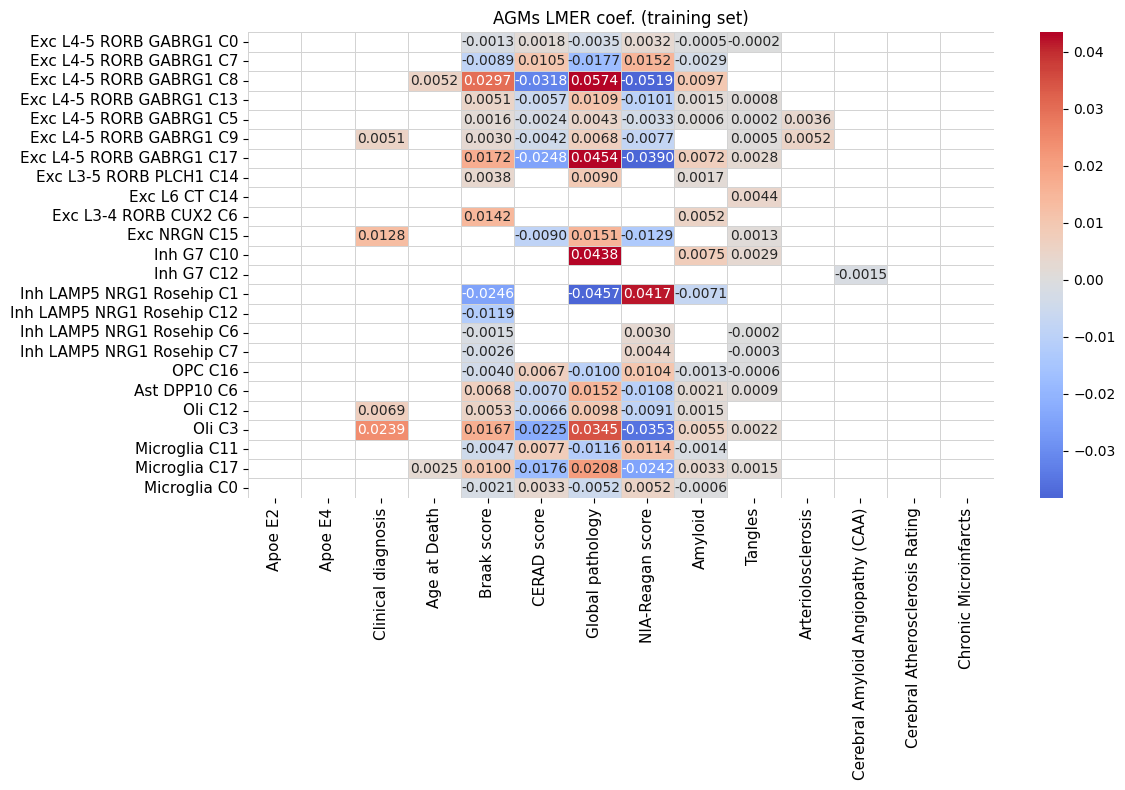

In [16]:

jnk =  train_df.rename(columns=pheno_mapping, index=clus_labels)
plt.figure(figsize=(12, 8))
sns.heatmap(jnk, cmap="coolwarm", center=0, annot=True, fmt=".4f", robust=True,linewidths=0.5,linecolor="lightgray")
plt.title("AGMs LMER coef. (training set)")
plt.yticks(fontsize=11)
plt.xticks(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(main_dir, "LMER_coefs_train.pdf"), dpi=300)

plt.show()


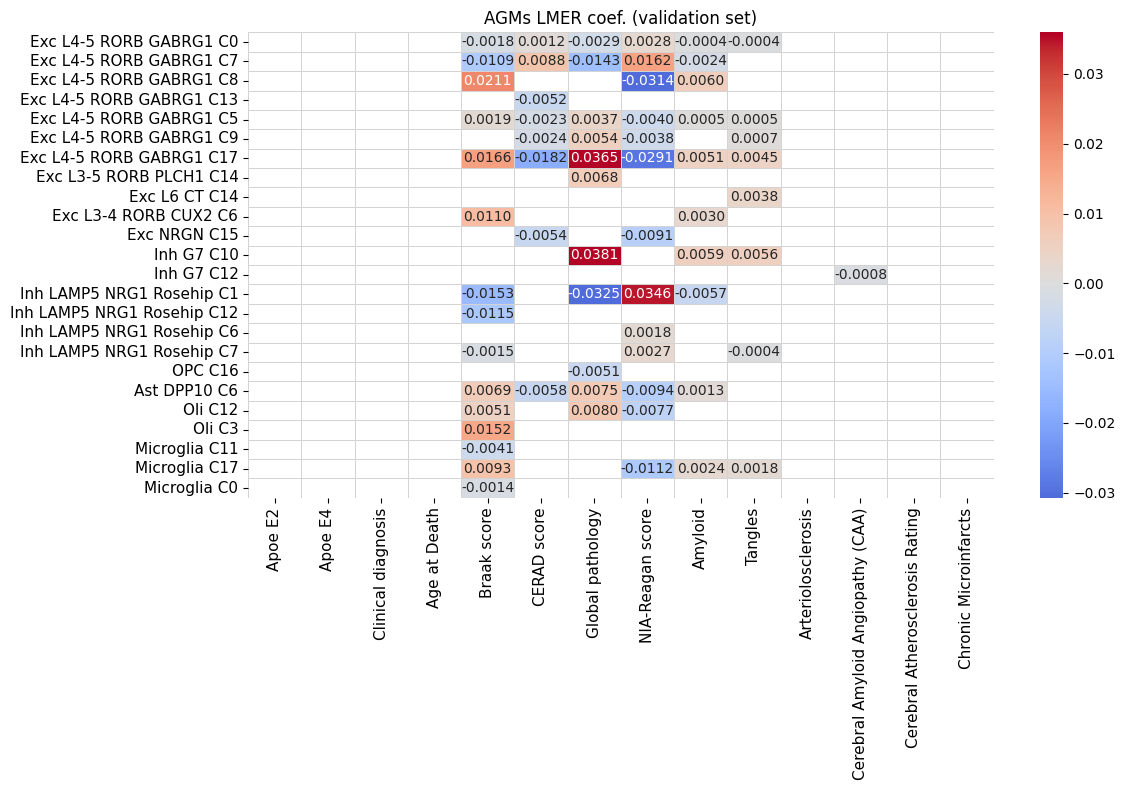

In [17]:
jnk =  validation_df.rename(columns=pheno_mapping, index=clus_labels)

plt.figure(figsize=(12, 8))
sns.heatmap(jnk, cmap="coolwarm", center=0, annot=True, fmt=".4f", robust=True, linewidths=0.5,linecolor="lightgray")
plt.title("AGMs LMER coef. (validation set)")
plt.yticks(fontsize=11)
plt.xticks(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(main_dir, "LMER_coefs_validation.pdf"), dpi=300)
plt.show()

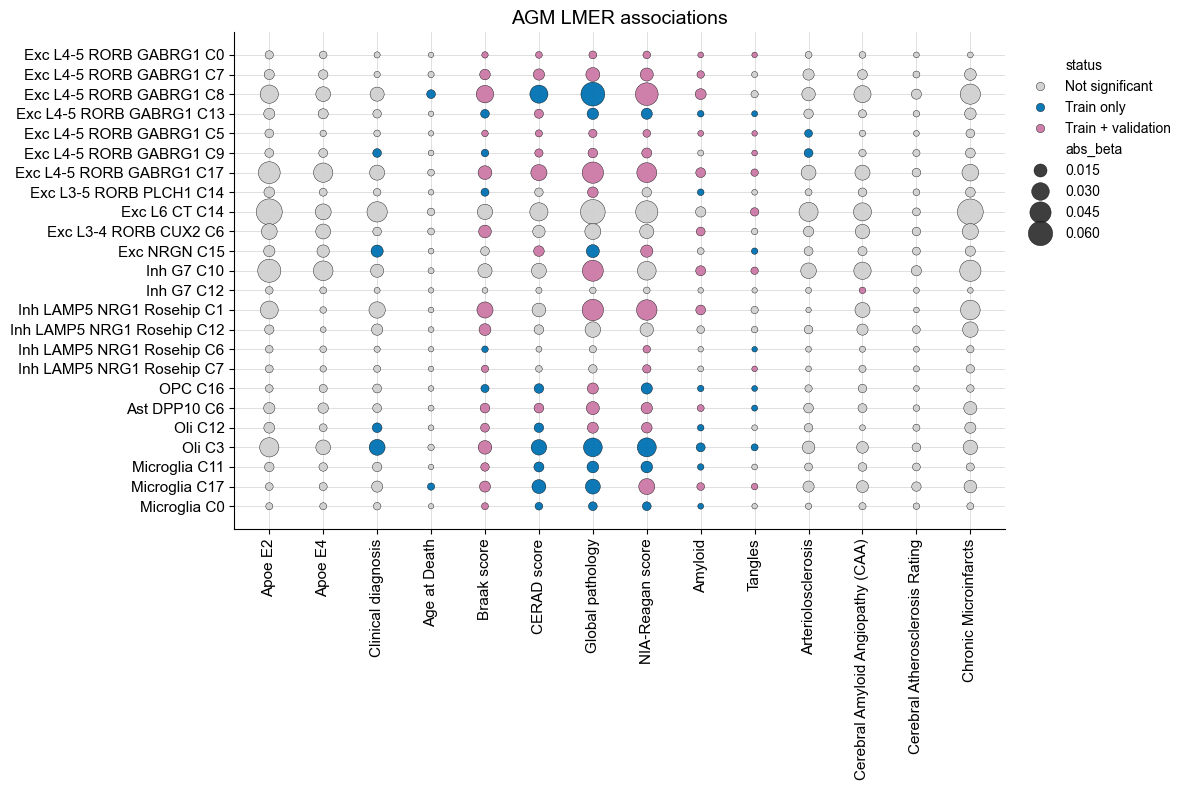

In [19]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns


# -----------------------
# Illustrator-friendly text
# -----------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"


# -----------------------
# Paths
# -----------------------
main_dir = Path("C:/Users/gabri/Documents/Data_projects/MCcharactertization/ROSMAP/Top_sets/Set309")

summary_file = main_dir / "Pipeline_files/Summary_files/all_clusters_pass_pval_nosex.csv"
lmer_dir = main_dir / "Pipeline_files/LMER_res"

cluster_list = pd.read_csv(summary_file)
clus_list = cluster_list["Cluster"].to_list()


# -----------------------
# Labels
# -----------------------
pheno_mapping = {
    "age_death": "Age at Death",
    "msex": "Sex: Men",
    "braaksc": "Braak score",
    "ceradsc": "CERAD score",
    "gpath": "Global pathology",
    "niareagansc": "NIA-Reagan score",
    "amyloid": "Amyloid",
    "tangles": "Tangles",
    "tdp_st4": "TDP-43 load stages",
    "arteriol_scler": "Arteriolosclerosis",
    "caa_4gp": "Cerebral Amyloid Angiopathy (CAA)",
    "cvda_4gp2": "Cerebral Atherosclerosis Rating",
    "ci_num2_mct": "Chronic Microinfarcts",
    "E2": "Apoe E2",
    "E4": "Apoe E4",
    "new_cogdx": "Clinical diagnosis",
}

clus_labels = {
    "Excitatory_ExcL45RORBGABRG1_Cluster_0": "Exc L4-5 RORB GABRG1 C0",
    "Excitatory_ExcL45RORBGABRG1_Cluster_7": "Exc L4-5 RORB GABRG1 C7",
    "Excitatory_ExcL45RORBGABRG1_Cluster_8": "Exc L4-5 RORB GABRG1 C8",
    "Excitatory_ExcL45RORBGABRG1_Cluster_13": "Exc L4-5 RORB GABRG1 C13",
    "Excitatory_ExcL45RORBGABRG1_Cluster_5": "Exc L4-5 RORB GABRG1 C5",
    "Excitatory_ExcL45RORBGABRG1_Cluster_9": "Exc L4-5 RORB GABRG1 C9",
    "Excitatory_ExcL45RORBGABRG1_Cluster_17": "Exc L4-5 RORB GABRG1 C17",

    "Excitatory_ExcL35RORBPLCH1_Cluster_14": "Exc L3-5 RORB PLCH1 C14",
    "Excitatory_ExcL6CT_Cluster_14": "Exc L6 CT C14",
    "Excitatory_ExcL34RORBCUX2_Cluster_6": "Exc L3-4 RORB CUX2 C6",
    "Excitatory_ExcNRGN_Cluster_15": "Exc NRGN C15",

    "Inhibitory_InhG7_Cluster_10": "Inh G7 C10",
    "Inhibitory_InhG7_Cluster_12": "Inh G7 C12",
    "Inhibitory_InhLAMP5NRG1Rosehip_Cluster_1": "Inh LAMP5 NRG1 Rosehip C1",
    "Inhibitory_InhLAMP5NRG1Rosehip_Cluster_12": "Inh LAMP5 NRG1 Rosehip C12",
    "Inhibitory_InhLAMP5NRG1Rosehip_Cluster_6": "Inh LAMP5 NRG1 Rosehip C6",
    "Inhibitory_InhLAMP5NRG1Rosehip_Cluster_7": "Inh LAMP5 NRG1 Rosehip C7",

    "OPCs_OPC_Cluster_16": "OPC C16",

    "Astrocytes_AstDPP10_Cluster_6": "Ast DPP10 C6",

    "Oligodendrocytes_Oli_Cluster_12": "Oli C12",
    "Oligodendrocytes_Oli_Cluster_3": "Oli C3",

    "Immune_Micall_Cluster_11": "Microglia C11",
    "Immune_Micall_Cluster_17": "Microglia C17",
    "Immune_Micall_Cluster_0": "Microglia C0",
}


# -----------------------
# Build full coefficient + p-value matrices
# -----------------------
def build_lmer_coef_pval_matrices(
    agm_list,
    path,
    data_type="train",
):
    """
    Builds coefficient and p-value matrices for AGMs.

    For train:
        coefficients from *_train_lmer_coef_nosex.csv
        p-values from *_train_adj_pvals_nosex.csv

    For validation:
        coefficients from *_validation_lmer_coef_nosex.csv
        p-values from *_validation_lmer_pvals_nosex.csv

    Returns
    -------
    coef_df : pd.DataFrame
        Rows = AGMs, columns = phenotypes, values = LMER coefficients.

    pval_df : pd.DataFrame
        Rows = AGMs, columns = phenotypes, values = adjusted p-values for train
        or nominal p-values for validation.
    """

    coef_rows = {}
    pval_rows = {}

    for agm in agm_list:

        if "_Cluster_" not in agm:
            print(f"Skipping malformed AGM name: {agm}")
            continue

        subtype, cluster_num = agm.rsplit("_Cluster_", 1)
        cluster_name = f"Cluster_{cluster_num}"

        coef_file = os.path.join(
            path,
            f"{subtype}_{data_type}_lmer_coef_nosex.csv"
        )

        if data_type == "train":
            pval_file = os.path.join(
                path,
                f"{subtype}_{data_type}_adj_pvals_nosex.csv"
            )
        else:
            pval_file = os.path.join(
                path,
                f"{subtype}_{data_type}_lmer_pvals_nosex.csv"
            )

        if not os.path.exists(coef_file):
            print(f"Missing coef file for {agm}: {coef_file}")
            continue

        if not os.path.exists(pval_file):
            print(f"Missing p-value file for {agm}: {pval_file}")
            continue

        coef_df = pd.read_csv(coef_file, index_col=0)
        pval_df = pd.read_csv(pval_file, index_col=0)

        if cluster_name not in coef_df.index:
            print(f"{cluster_name} not found in coef file for {agm}")
            continue

        if cluster_name not in pval_df.index:
            print(f"{cluster_name} not found in p-value file for {agm}")
            continue

        coef_row = coef_df.loc[cluster_name].copy()
        pval_row = pval_df.loc[cluster_name].copy()

        common_cols = coef_row.index.intersection(pval_row.index)
        coef_row = coef_row[common_cols]
        pval_row = pval_row[common_cols]

        coef_rows[agm] = coef_row
        pval_rows[agm] = pval_row

    coef_out = pd.DataFrame.from_dict(coef_rows, orient="index")
    pval_out = pd.DataFrame.from_dict(pval_rows, orient="index")

    return coef_out, pval_out


train_coef_df, train_pval_df = build_lmer_coef_pval_matrices(
    agm_list=clus_list,
    path=lmer_dir,
    data_type="train",
)

validation_coef_df, validation_pval_df = build_lmer_coef_pval_matrices(
    agm_list=clus_list,
    path=lmer_dir,
    data_type="validation",
)


# -----------------------
# Build dotplot-ready dataframe
# -----------------------
def make_agm_dotplot_df(
    train_coef_df,
    train_pval_df,
    validation_coef_df,
    validation_pval_df,
    alpha_train=0.05,
    alpha_validation=0.05,
):
    """
    Creates a long dataframe for dotplot visualization.

    Status categories:
        Not significant
        Train only
        Train + validation
    """

    # Use only AGMs and phenotypes present in all matrices
    common_rows = (
        train_coef_df.index
        .intersection(train_pval_df.index)
        .intersection(validation_coef_df.index)
        .intersection(validation_pval_df.index)
    )

    common_cols = (
        train_coef_df.columns
        .intersection(train_pval_df.columns)
        .intersection(validation_coef_df.columns)
        .intersection(validation_pval_df.columns)
    )

    train_coef = train_coef_df.loc[common_rows, common_cols]
    train_pval = train_pval_df.loc[common_rows, common_cols]
    val_coef = validation_coef_df.loc[common_rows, common_cols]
    val_pval = validation_pval_df.loc[common_rows, common_cols]

    rows = []

    for agm in common_rows:
        for pheno in common_cols:

            train_beta = train_coef.loc[agm, pheno]
            train_p = train_pval.loc[agm, pheno]

            val_beta = val_coef.loc[agm, pheno]
            val_p = val_pval.loc[agm, pheno]

            train_sig = pd.notna(train_p) and train_p < alpha_train
            val_sig = pd.notna(val_p) and val_p < alpha_validation

            if train_sig and val_sig:
                status = "Train + validation"
            elif train_sig and not val_sig:
                status = "Train only"
            else:
                status = "Not significant"

            rows.append({
                "AGM": agm,
                "Phenotype": pheno,
                "train_beta": train_beta,
                "validation_beta": val_beta,
                "train_p": train_p,
                "validation_p": val_p,
                "train_sig": train_sig,
                "validation_sig": val_sig,
                "status": status,
                "abs_beta": abs(train_beta) if pd.notna(train_beta) else np.nan,
            })

    dot_df = pd.DataFrame(rows)

    return dot_df


dot_df = make_agm_dotplot_df(
    train_coef_df=train_coef_df,
    train_pval_df=train_pval_df,
    validation_coef_df=validation_coef_df,
    validation_pval_df=validation_pval_df,
    alpha_train=0.05,
    alpha_validation=0.05,
)


# -----------------------
# Apply readable labels
# -----------------------
dot_df["AGM_label"] = dot_df["AGM"].map(clus_labels).fillna(dot_df["AGM"])
dot_df["Phenotype_label"] = dot_df["Phenotype"].map(pheno_mapping).fillna(dot_df["Phenotype"])


# Keep the same order as your heatmap
agm_order = [clus_labels.get(x, x) for x in train_coef_df.index if x in dot_df["AGM"].unique()]
pheno_order = [pheno_mapping.get(x, x) for x in train_coef_df.columns if x in dot_df["Phenotype"].unique()]

dot_df["AGM_label"] = pd.Categorical(
    dot_df["AGM_label"],
    categories=agm_order,
    ordered=True,
)

dot_df["Phenotype_label"] = pd.Categorical(
    dot_df["Phenotype_label"],
    categories=pheno_order,
    ordered=True,
)

dot_df = dot_df.sort_values(["AGM_label", "Phenotype_label"])


# -----------------------
# Optional: control dot size range
# -----------------------
# This makes very tiny coefficients still visible.
# Increase max_size if you want bigger dots.
min_size = 15
max_size = 350

coef_max = dot_df["abs_beta"].max()

dot_df["dot_size"] = (
    min_size
    + (dot_df["abs_beta"] / coef_max) * (max_size - min_size)
)


# -----------------------
# Plot
# -----------------------
palette = {
    "Not significant": "#D0D0D0",
    "Train only": "#0072B2",
    "Train + validation": "#CC79A7",
}

status_order = [
    "Not significant",
    "Train only",
    "Train + validation",
]

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(
    data=dot_df,
    x="Phenotype_label",
    y="AGM_label",
    hue="status",
    hue_order=status_order,
    palette=palette,
    size="abs_beta",
    sizes=(min_size, max_size),
    edgecolor="black",
    linewidth=0.3,
    alpha=0.95,
    ax=ax,
)

ax.set_title("AGM LMER associations", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("")

ax.tick_params(axis="x", labelrotation=90, labelsize=11)
ax.tick_params(axis="y", labelsize=11)

# Grid behind dots
ax.set_axisbelow(True)
ax.grid(axis="both", color="lightgray", linewidth=0.5)

# Clean spines
sns.despine(ax=ax, left=False, bottom=False)

# Move legend outside
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    frameon=False,
    title=" "
)

plt.tight_layout()

plt.savefig(main_dir / "LMER_AGM_dotplot_train_validation.pdf", dpi=300, bbox_inches="tight")
plt.savefig(main_dir / "LMER_AGM_dotplot_train_validation.svg", dpi=300, bbox_inches="tight")

plt.show()